In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.11.0+cpu'

In [7]:
# Setting up the dataset
weight = 0.3
bias = 0.9

# Creating a custom dataset
start = 0
end = 1
step = 0.02

# Settng the linear regression formula
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

In [10]:
# Spliting my dataset into tran, test, and eval mode
train_set = int(0.8 * len(X))
X_train, y_train = X[:train_set], X[:train_set]
X_test, y_test = X[train_set:], X[train_set:]
len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

In [40]:
# Visulaizze the data as it is of now
def plot_predictions(train_data=X_train,
                    train_label=y_train,
                    test_data=X_test,
                    test_label=y_test,
                    predictions=None):
    plt.figure(figsize=(10, 7))
    plt.scatter(train_data, train_label, c="b", s=4, label="Training Data")
    plt.scatter(test_data, test_label, c="g", s=4, label="Testing Data")

    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

    plt.legend(prop={"size": 14});

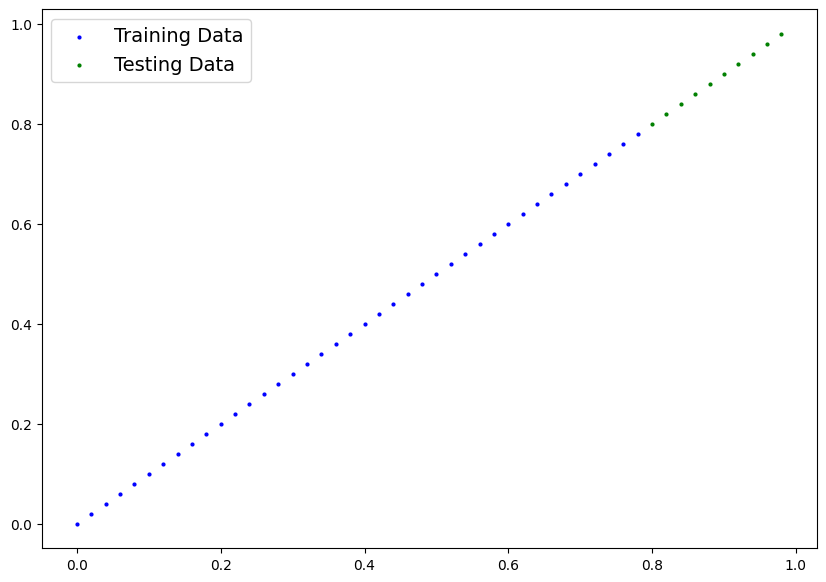

In [41]:
plot_predictions()

In [42]:
# Training the model
class LinearRegressionV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.weights = nn.Parameter(torch.randn(1,
                                                requires_grad=True,
                                                dtype=torch.float
                                               ))

        self.bias = nn.Parameter(torch.randn(1,
                                           dtype=torch.float,
                                           requires_grad=True))

    def forward(self, X: torch.Tensor)-> torch.Tensor:
        return self.weights * X + self.bias
        

In [43]:
model_1 = LinearRegressionV1()
model_1.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [44]:
# setting up the loss function and the Optimizer 
loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(params=model_1.parameters(),
                           lr=0.01)

In [81]:
torch.manual_seed(42)

# Set the number of epochs (how many times the model will pass over the training data)
epochs = 300

# Create empty loss lists to track values
train_loss_values = []
test_loss_values = []
epoch_count = []

for epoch in range(epochs):
    ### Training

    # Put model in training mode (this is the default state of a model)
    model_1.train()

    # 1. Forward pass on train data using the forward() method inside 
    y_pred = model_1(X_train)
    # print(y_pred)

    # 2. Calculate the loss (how different are our models predictions to the ground truth)
    loss = loss_fn(y_pred, y_train)

    # 3. Zero grad of the optimizer
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Progress the optimizer
    optimizer.step()

    ### Testing

    # Put the model in evaluation mode
    model_1.eval()

    with torch.inference_mode():
      # 1. Forward pass on test data
      test_pred = model_1(X_test)

      # 2. Caculate loss on test data
      test_loss = loss_fn(test_pred, y_test.type(torch.float)) # predictions come in torch.float datatype, so comparisons need to be done with tensors of the same type

      # Print out what's happening
      if epoch % 20 == 0:
            epoch_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")

Epoch: 0 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 20 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 40 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 60 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 80 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 100 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 120 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 140 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 160 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 180 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 200 | MAE Train Loss: 0.0034436702262610197 | MAE Test Loss: 0.007138299755752087 
Epoch: 220 | MAE

In [82]:
# Making Predictions with the model
model_1.eval()

with torch.inference_mode():
    y_preds = model_1(X_test)
y_preds

tensor([[0.7942],
        [0.8141],
        [0.8340],
        [0.8538],
        [0.8737],
        [0.8936],
        [0.9135],
        [0.9334],
        [0.9533],
        [0.9731]])

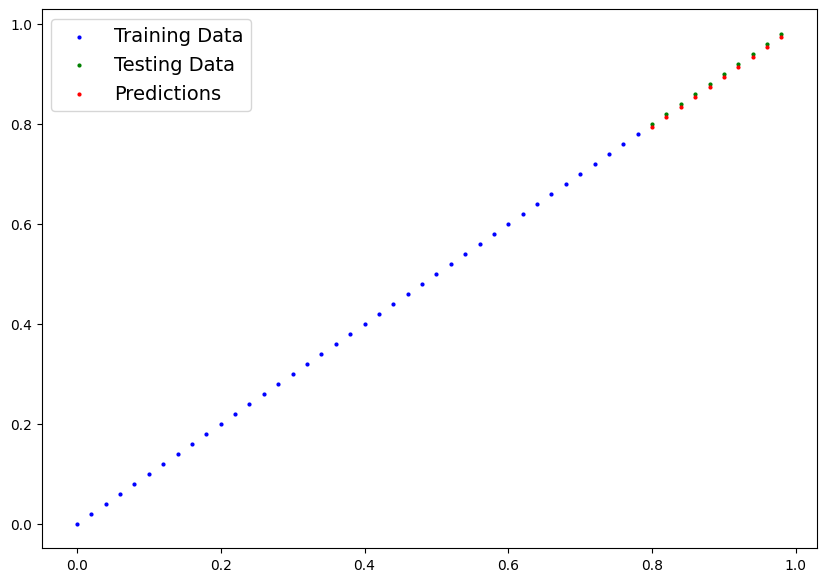

In [83]:
plot_predictions(predictions=y_preds)

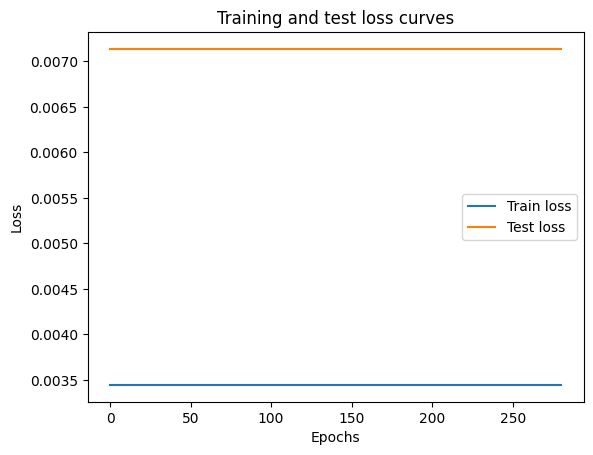

In [84]:
# Plot the loss curves
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

In [86]:
# Saving my model
from pathlib import Path

PATH_NAME = Path("models")
PATH_NAME.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "01_Pytorch_exercise_workflow_model_1.pth"
MODEL_SAVE_PATH = PATH_NAME / MODEL_NAME

print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to: models\01_Pytorch_exercise_workflow_model_1.pth


In [88]:
loaded_model_1 = LinearRegressionV1()

loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))

print(f"Loaded Model:\n{loaded_model_1}")

Loaded Model:
LinearRegressionV1()


In [89]:
# Evaluate our loaded model
loaded_model_1.eval()
with torch.inference_mode():
    loaded_model_1_preds = loaded_model_1(X_test)
y_preds == loaded_model_1_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])